# Introduction to Data Science 2026

# Bonus exercises

## Exercise 1: EDA of unemployed highly educated people in Finland

In this assignment, you will explore time series data on unemployment of highly educated people in Finland combined with two datasets of your own choosing. The idea of the assignment is to look into how the unemployed highly educated population varies over time and across different areas by using the data wrangling, exploratory data analysis, and visualization tools discussed during the course.

First, please download the Statistics Finland's CSV dataset (available in the course MOOC Materials) that contains data on employment and unemployment numbers grouped by level of education, province, and year.

Read in the data to a data frame, and have a look at the rows and columns it contains. For ease of use, you can set the year column as the index. Perform any other preprocessing you see fit. If you are working in Python, you can do this using the pandas library. 

**Hint**: you can also create new useful columns using the existing ones. 

In [ ]:
## Use this cell for your code

# ============================================================
# Setup, read in the Statistics Finland CSV, and inspect levels
# ============================================================

%matplotlib inline
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": ":",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 8,
})

# locate files
HERE = os.getcwd()
try:                                    # works when run as a plain .py script
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    pass

SEARCH_DIRS = [os.path.join(HERE, "data"), HERE, "data", ".", "..",
               os.path.join(HERE, "bonus_ex1_data"), "bonus_ex1_data"]


def find_file(name):
    # Return the first existing path for *name* among a few sensible folders.
    for d in SEARCH_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(
        "%s not found. Looked in: %s" % (name, ", ".join(SEARCH_DIRS)))


UNEMP_CSV = find_file("unemployment_data.csv")
print("Reading:", UNEMP_CSV)

# cp1252 -- the file contains "Åland", which is not valid UTF-8 here.
raw = pd.read_csv(UNEMP_CSV, encoding="cp1252")

print("shape:", raw.shape)
print("\ncolumns and dtypes:")
print(raw.dtypes.to_string())
print("\nfirst rows:")
print(raw.head(8).to_string(index=False))

# inspect levels
print("Year      : %d - %d  (%d distinct)" % (raw["Year"].min(), raw["Year"].max(), raw["Year"].nunique()))
print("Areas     : %d distinct" % raw["Area"].nunique())
print("Activity  :", raw["Main type of activity"].unique().tolist())
print("Education :", raw["Level of education"].unique().tolist())
print("Missing values per column:\n", raw.isna().sum().to_string())

print("\nRows per (activity, education) cell -- the panel is balanced:")
print(raw.groupby(["Main type of activity", "Level of education"]).size().to_string())

print("\nAll 19 regions:")
for a in sorted(raw["Area"].unique()):
    print("  ", a)

# ============================================================
# Reshape long -> one row per (year, province), derived columns
# ============================================================

# tidy long -> one row / year-region
df = raw.copy()
df["Area"] = df["Area"].str.strip()
df["region_code"] = df["Area"].str.extract(r"^(MK\d+)")
df["region"] = df["Area"].str.replace(r"^MK\d+\s*", "", regex=True)
df["edu"] = np.where(df["Level of education"].str.startswith("Total"), "total", "masters")

w = df.pivot_table(index=["Year", "region_code", "region"],
                   columns=["Main type of activity", "edu"],
                   values="Population 31 Dec", aggfunc="sum")

# flatten the MultiIndex explicitly: ("Employed", "masters") -> "employed_masters".
# (Renaming MultiIndex columns with tuple keys is fragile across pandas versions.)
w.columns = ["%s_%s" % (a, b) for a, b in w.columns]
w.columns = [c.lower() for c in w.columns]
w = w.rename(columns={"total_total":      "pop_total",
                      "total_masters":    "pop_masters",
                      "employed_total":   "emp_total",
                      "employed_masters": "emp_masters",
                      "unemployed_total": "unemp_total",
                      "unemployed_masters": "unemp_masters"}).reset_index()

# derived columns
w["lf_total"]   = w["emp_total"]   + w["unemp_total"]      # labour force, all education levels
w["lf_masters"] = w["emp_masters"] + w["unemp_masters"]    # labour force, Master's level or above

w["urate_total_pct"]   = 100 * w["unemp_total"]   / w["lf_total"]
w["urate_masters_pct"] = 100 * w["unemp_masters"] / w["lf_masters"]

w["masters_share_lf_pct"]  = 100 * w["lf_masters"]  / w["lf_total"]
w["masters_share_pop_pct"] = 100 * w["pop_masters"] / w["pop_total"]
w["not_in_lf"]             = w["pop_total"] - w["lf_total"]   # students, pensioners, others

w = w.sort_values(["Year", "region_code"]).reset_index(drop=True)

print("Tidy panel:", w.shape)
print(w.head(3).to_string(index=False))
print("\nSanity checks")
print("  rows with a zero/NaN Master's labour force :", int((w["lf_masters"] <= 0).sum() + w["urate_masters_pct"].isna().sum()))
print("  infinite rates                             :", int(np.isinf(w["urate_masters_pct"]).sum()))
print("  'Total' > 'Employed+Unemployed' everywhere  :", bool((w["not_in_lf"] > 0).all()),
      " (min gap %d persons)" % w["not_in_lf"].min())

# ============================================================
# National aggregate (sum over provinces), Year as the index
# ============================================================

# national aggregate, Year as index
nat = (w.groupby("Year")[["pop_total", "pop_masters", "emp_total", "emp_masters",
                          "unemp_total", "unemp_masters", "lf_total", "lf_masters",
                          "not_in_lf"]]
         .sum())

nat["urate_total_pct"]       = 100 * nat["unemp_total"]   / nat["lf_total"]
nat["urate_masters_pct"]     = 100 * nat["unemp_masters"] / nat["lf_masters"]
nat["masters_share_lf_pct"]  = 100 * nat["lf_masters"]    / nat["lf_total"]
nat["masters_share_pop_pct"] = 100 * nat["pop_masters"]   / nat["pop_total"]
nat["ratio_protective"]      = nat["urate_masters_pct"]   / nat["urate_total_pct"]
nat["unemp_share_masters_pct"] = 100 * nat["unemp_masters"] / nat["unemp_total"]

print("National panel (sum over the 19 regions), Year as index:", nat.shape)
print(nat[["lf_total", "unemp_total", "urate_total_pct",
           "lf_masters", "unemp_masters", "urate_masters_pct",
           "masters_share_lf_pct", "ratio_protective"]]
      .round(2).to_string())


Reading: c:\Users\zhizh\Documents\GitHub\DataSciencePrivateRepo\Bonus Exercises\unemployment_data.csv
shape: (4218, 5)

columns and dtypes:
Year                     int64
Area                       str
Main type of activity      str
Level of education         str
Population 31 Dec        int64

first rows:
 Year                   Area Main type of activity                                               Level of education  Population 31 Dec
 1987           MK01 Uusimaa                 Total                                                            Total            1199530
 1987           MK01 Uusimaa                 Total 7-8 Master's or equivalent level or doctoral or equivalent level              65757
 1987           MK01 Uusimaa              Employed                                                            Total             653347
 1987           MK01 Uusimaa              Employed 7-8 Master's or equivalent level or doctoral or equivalent level              55702
 1987           M

Next, find two time series datasets of your choice to combine with the unemployment data. These can be time series data on factors that you are interested in that might be connected to unemployment, and should cover at least some of the same years as the unemployment data. Please find the datasets from some source other than Statistics Finland (Tilastokeskus).

Read in your datasets, perform any necessary cleaning (such as handling missing values or removing unnecessary columns, et cetera). Preprocess the data so that the features are presented on a yearly level. Then, combine the preprocessed datasets to the unemployment data using the year column to link the datasets.

In [ ]:
## Use this cell for your code

# ============================================================
# Two external annual series (World Bank, not Statistics Finland)
# ============================================================

import json
import urllib.request

WB_INDICATORS = {
    "gdp_growth_pct":        "NY.GDP.MKTP.KD.ZG",   # GDP growth, annual %
    "rd_expenditure_pct_gdp": "GB.XPD.RSDV.GD.ZS",   # R&D expenditure, % of GDP
    "population_15_64":      "SP.POP.1564.TO",       # population aged 15-64, total
}


def fetch_worldbank(country="FIN", start=1987, end=2025, outdir=None):
    # Download the yearly World Bank series used here and store them as CSVs.
    #
    # Run this once if you want to refresh the external data; the notebook otherwise
    # reads the CSVs that ship with it. Returns a dict name -> DataFrame.
    frames = {}
    for name, ind in WB_INDICATORS.items():
        url = ("https://api.worldbank.org/v2/country/%s/indicator/%s"
               "?date=%d:%d&format=json&per_page=100" % (country, ind, start, end))
        with urllib.request.urlopen(url, timeout=60) as r:
            payload = json.loads(r.read())
        rows = [(int(x["date"]), float(x["value"]))
                for x in payload[1] if x.get("value") is not None]
        f = pd.DataFrame(sorted(rows), columns=["Year", name])
        frames[name] = f
        if outdir:
            os.makedirs(outdir, exist_ok=True)
            f.to_csv(os.path.join(outdir, "%s.csv" % name), index=False)
        print("  %-24s %d yearly values, %d-%d" % (name, len(f), f["Year"].min(), f["Year"].max()))
    return frames


def load_external(name):
    # Read the stored World Bank CSV, or fetch it from the API if the file is missing.
    # Normalise the year column name so the merge key is always "Year".
    try:
        f = pd.read_csv(find_file("%s.csv" % name))
        return f.rename(columns={c: "Year" for c in f.columns if c.lower() == "year"})
    except FileNotFoundError:
        print("  %s.csv missing -> fetching from the World Bank API" % name)
        return fetch_worldbank()[name]


print("Loading external series:")
gdp = load_external("gdp_growth_pct")
rnd = load_external("rd_expenditure_pct_gdp")
pop = load_external("population_15_64")

# cleaning: annual level, one row / year
for frame in (gdp, rnd, pop):
    frame["Year"] = frame["Year"].astype(int)
    assert frame["Year"].is_unique, "external series must be yearly"

wb = (gdp.merge(rnd, on="Year", how="outer")
         .merge(pop, on="Year", how="outer")
         .sort_values("Year")
         .reset_index(drop=True))

print("\nWorld Bank frame:", wb.shape)
print("non-missing values per column:\n", wb.notna().sum().to_string())
print("\noverlap with the unemployment panel (%d-%d):" % (nat.index.min(), nat.index.max()))
print(wb[(wb.Year >= nat.index.min()) & (wb.Year <= nat.index.max())].tail(6).to_string(index=False))

# ============================================================
# Combine on Year (national and regional merged frames), lags
# ============================================================

# combine on Year
# The external series are national and annual; the unemployment panel is regional and annual.
# Merging on Year therefore attaches the SAME national value to every region in that year
# (a left join keeps all 19 x 37 regional rows).
# Left join keeps every regional row. The regenerated GDP series now covers the whole
# unemployment panel (1987-2023); R&D intensity is only available from 1996.
merged = nat.reset_index().merge(wb, on="Year", how="left").set_index("Year")
print("national merged frame:", merged.shape, "| years", merged.index.min(), "-", merged.index.max())

regional = w.merge(wb, on="Year", how="left")
print("regional merged frame:", regional.shape,
      "| GDP growth available for", int(regional["gdp_growth_pct"].notna().sum()), "of", len(regional), "rows")

# lagged macro drivers (does the cycle lead unemployment?)
for lag in (1, 2, 3):
    merged["gdp_growth_lag%d" % lag] = merged["gdp_growth_pct"].shift(lag)
    regional["gdp_growth_lag%d" % lag] = regional["gdp_growth_pct"].shift(lag)

print("\nMerged national table (selected columns):")
print(merged[["urate_total_pct", "urate_masters_pct", "masters_share_lf_pct",
              "gdp_growth_pct", "rd_expenditure_pct_gdp", "population_15_64"]]
      .tail(12).round(2).to_string())

Loading external series:
  gdp_growth_pct.csv missing -> fetching from the World Bank API
  gdp_growth_pct           39 yearly values, 1987-2025
  rd_expenditure_pct_gdp   28 yearly values, 1996-2023
  population_15_64         39 yearly values, 1987-2025
  rd_expenditure_pct_gdp.csv missing -> fetching from the World Bank API
  gdp_growth_pct           39 yearly values, 1987-2025
  rd_expenditure_pct_gdp   28 yearly values, 1996-2023
  population_15_64         39 yearly values, 1987-2025
  population_15_64.csv missing -> fetching from the World Bank API
  gdp_growth_pct           39 yearly values, 1987-2025
  rd_expenditure_pct_gdp   28 yearly values, 1996-2023
  population_15_64         39 yearly values, 1987-2025

World Bank frame: (39, 4)
non-missing values per column:
 Year                      39
gdp_growth_pct            39
rd_expenditure_pct_gdp    28
population_15_64          39

overlap with the unemployment panel (1987-2023):
 Year  gdp_growth_pct  rd_expenditure_pct_gdp  pop

Perform exploratory data analysis on your merged dataset. You can use methods of your choice to compute useful statistics on the data, and to visualize different features and the interactions between them. Focus on the question of whether high education level (Master's level) and other factors in your merged dataset are associated with unemployment.

=== National descriptive statistics, 1987-2023 ===
(GDP growth covers the full 1987-2023 panel; R&D intensity only 1996-2023)
                        count      mean      std      min      25%      50%       75%       max
urate_total_pct          37.0     12.13     4.11     4.36     9.78    11.68     13.75     22.18
urate_masters_pct        37.0      4.26     1.53     1.11     3.62     4.20      5.12      7.02
ratio_protective         37.0      0.35     0.10     0.19     0.27     0.35      0.42      0.50
masters_share_lf_pct     37.0     10.36     3.65     4.88     7.32    10.05     13.28     16.98
unemp_masters            37.0  12123.54  6905.22  1410.00  7728.00  9990.00  17772.00  25078.00
gdp_growth_pct           37.0      1.75     3.22    -8.08     0.47     2.57      4.01      6.40
rd_expenditure_pct_gdp   28.0      3.13     0.33     2.46     2.87     3.18      3.33      3.73

=== Turning points ===
  early-1990s depression     1993: total 22.18% | Master's 6.49% | protective rati

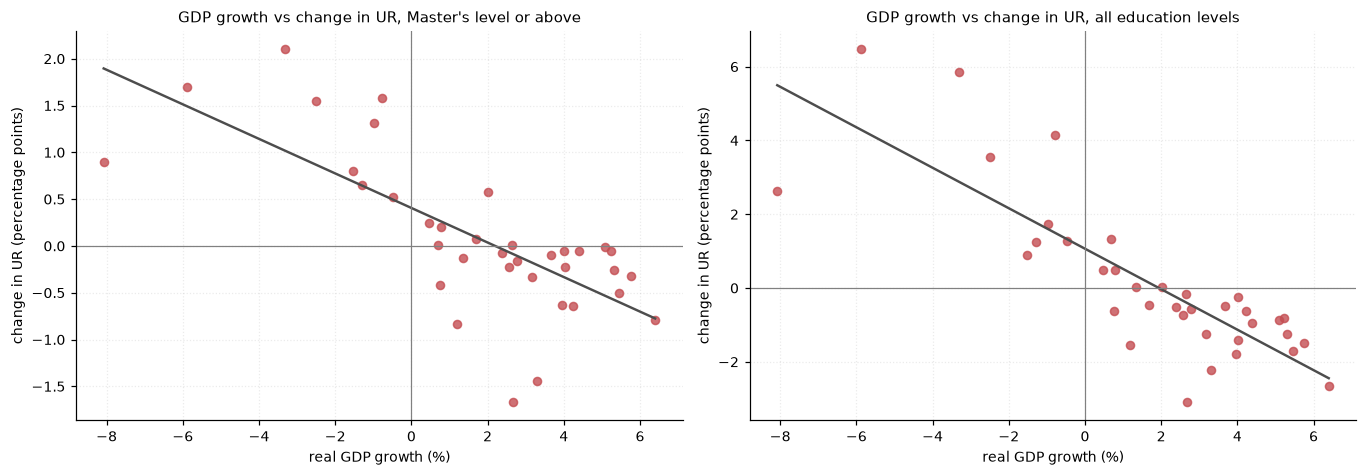

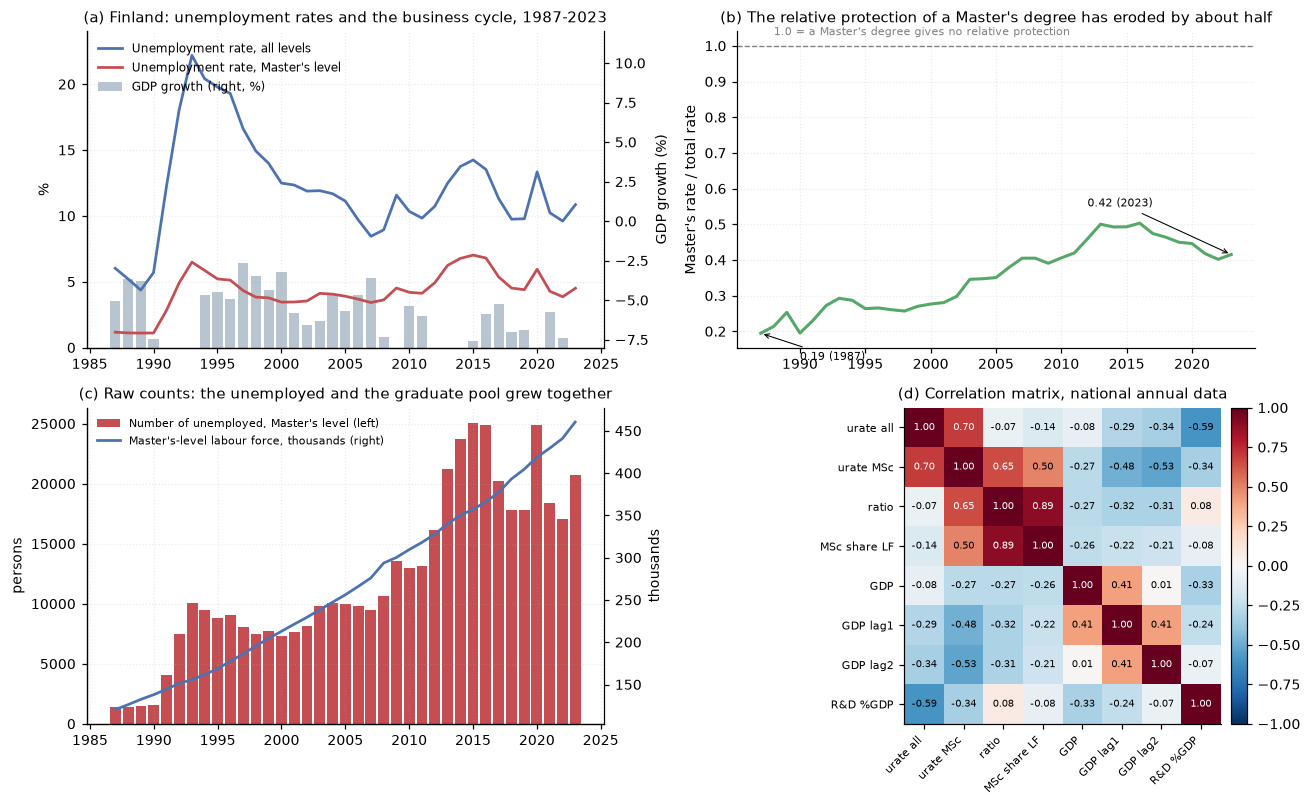

In [ ]:
## Use this cell for your code

# ============================================================
# Descriptive statistics and historical turning points
# ============================================================

# descriptive statistics
cols = ["urate_total_pct", "urate_masters_pct", "ratio_protective",
        "masters_share_lf_pct", "unemp_masters", "gdp_growth_pct", "rd_expenditure_pct_gdp"]
print("=== National descriptive statistics, 1987-2023 ===")
print("(GDP growth covers the full 1987-2023 panel; R&D intensity only 1996-2023)")
print(merged[cols].describe().T.round(2).to_string())

print("\n=== Turning points ===")
for label, y in [("early-1990s depression", 1993), ("pre-crisis boom", 2007),
                 ("global financial crisis", 2009), ("2010s stagnation peak", 2015),
                 ("pandemic", 2020), ("most recent year", 2023)]:
    r = merged.loc[y]
    gdp_txt = "%+.2f%%" % r.gdp_growth_pct if pd.notna(r.gdp_growth_pct) else "n/a (pre-1990)"
    print("  %-26s %d: total %.2f%% | Master's %.2f%% | protective ratio %.2f | GDP %s"
          % (label, y, r.urate_total_pct, r.urate_masters_pct, r.ratio_protective, gdp_txt))

print("\n=== Extremes of the Master's-level unemployment rate ===")
s = merged["urate_masters_pct"]
print("  min  %.2f%% in %d" % (s.min(), s.idxmin()))
print("  max  %.2f%% in %d" % (s.max(), s.idxmax()))
print("  1987 %.2f%%  ->  2023 %.2f%%   (change %+.2f pp, i.e. x%.1f)"
      % (s.loc[1987], s.loc[2023], s.loc[2023] - s.loc[1987], s.loc[2023] / s.loc[1987]))

print("\n=== Composition: how much did the graduate pool grow? ===")
print("  Master's-level labour force : %d (1987) -> %d (2023), x%.1f"
      % (merged.lf_masters.loc[1987], merged.lf_masters.loc[2023],
         merged.lf_masters.loc[2023] / merged.lf_masters.loc[1987]))
print("  share of total labour force : %.2f%% -> %.2f%%"
      % (merged.masters_share_lf_pct.loc[1987], merged.masters_share_lf_pct.loc[2023]))
print("  unemployed Master's-level   : %d -> %d (peak %d in %d)"
      % (merged.unemp_masters.loc[1987], merged.unemp_masters.loc[2023],
         merged.unemp_masters.max(), merged.unemp_masters.idxmax()))
print("  protective ratio            : %.2f (1987) -> %.2f (2023), peak %.2f in %d"
      % (merged.ratio_protective.loc[1987], merged.ratio_protective.loc[2023],
         merged.ratio_protective.max(), merged.ratio_protective.idxmax()))

# ============================================================
# Associations: levels, lags, and the differenced business cycle
# ============================================================

# association with the two external series
def corr(driver, target):
    # Pearson r between a driver column and a target column of the merged national frame.
    d = merged[[target, driver]].dropna()
    if len(d) < 5 or d[target].nunique() < 2 or d[driver].nunique() < 2:
        return np.nan, len(d)
    return float(np.corrcoef(d[target], d[driver])[0, 1]), len(d)


print("=== Pearson correlations, national annual data ===")
print("(association only -- see the caveat below)\n")
drivers = ["gdp_growth_pct", "rd_expenditure_pct_gdp", "masters_share_lf_pct",
           "population_15_64", "gdp_growth_lag1", "gdp_growth_lag2", "gdp_growth_lag3"]
rows = []
for d in drivers:
    r_m, n_m = corr(d, "urate_masters_pct")
    r_t, n_t = corr(d, "urate_total_pct")
    rows.append([d, r_m, n_m, r_t, n_t])
tab = pd.DataFrame(rows, columns=["driver", "r vs Master's rate", "n", "r vs total rate", "n "])
print(tab.round(3).to_string(index=False))

print("\n=== Reading ===")
print("* In LEVELS, contemporaneous GDP growth is only weakly/moderately associated with the")
print("  Master's rate (r = %+.2f); the association strengthens with a 1-2 year lag"
      % tab.loc[tab.driver == 'gdp_growth_pct', "r vs Master's rate"].iloc[0])
print("  (r = %+.2f at lag 1, %+.2f at lag 2)."
      % (tab.loc[tab.driver == 'gdp_growth_lag1', "r vs Master's rate"].iloc[0],
         tab.loc[tab.driver == 'gdp_growth_lag2', "r vs Master's rate"].iloc[0]))
print("* R&D intensity is negatively associated with both rates, more strongly with the")
print("  overall rate than with the Master's-level rate.")
print("* The Master's share of the labour force is POSITIVELY associated with the Master's")
print("  rate and NEGATIVELY with the total rate -- a composition effect, discussed below.")

print("\n=== Caveat (important) ===")
print("n = 36-37 annual observations of strongly autocorrelated, trended series. The")
print("effective sample size is much smaller than n, so these r values are descriptive")
print("summaries, not evidence of causation, and their usual p-values are not trustworthy.")
print("The next cell applies the differenced version; a further step would be an ARIMAX / error-correction model.")

# DIFFERENCED business-cycle analysis
# Levels of two strongly trended series can mislead (spurious correlation). The direct
# remedy is to ask whether GDP contractions coincide with year-to-year RISES in unemployment.
merged["d_urate_masters_pct"] = merged["urate_masters_pct"].diff()
merged["d_urate_total_pct"]   = merged["urate_total_pct"].diff()

dd = merged.dropna(subset=["gdp_growth_pct", "d_urate_masters_pct"])
r_m = np.corrcoef(dd["gdp_growth_pct"], dd["d_urate_masters_pct"])[0, 1]
r_t = np.corrcoef(dd["gdp_growth_pct"], dd["d_urate_total_pct"])[0, 1]
print("GDP growth vs year-to-year CHANGE in the unemployment rate (n = %d):" % len(dd))
print("  Master's level or above : r = %+.2f" % r_m)
print("  all education levels    : r = %+.2f" % r_t)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharex=True)
for ax, dy, t in ((axes[0], "d_urate_masters_pct", "Master's level or above"),
                  (axes[1], "d_urate_total_pct", "all education levels")):
    x = dd["gdp_growth_pct"].values
    y = dd[dy].values
    ax.scatter(x, y, s=28, color="#c44e52", alpha=0.8)
    b, a = np.polyfit(x, y, 1)
    gx = np.linspace(x.min(), x.max(), 50)
    ax.plot(gx, a + b * gx, color="0.3", lw=1.6)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel("real GDP growth (%)")
    ax.set_ylabel("change in UR (percentage points)")
    ax.set_title("GDP growth vs change in UR, %s" % t)
fig.tight_layout()
plt.show()

# ============================================================
# Figures: national picture and the differenced cycle
# ============================================================

# FIGURE 1: national picture
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))

# (a) both unemployment rates + GDP growth
ax = axes[0, 0]
ax.bar(merged.index, merged["gdp_growth_pct"], color="#b8c4d0", width=0.8,
       label="GDP growth (right, %)")
ax.plot(merged.index, merged["urate_total_pct"], color="#4c72b0", lw=1.8, label="Unemployment rate, all levels")
ax.plot(merged.index, merged["urate_masters_pct"], color="#c44e52", lw=1.8, label="Unemployment rate, Master's level")
ax.set_ylabel("%")
ax.set_title("(a) Finland: unemployment rates and the business cycle, 1987-2023")
ax2 = ax.twinx()
ax2.set_ylim(-8, 12); ax2.set_ylabel("GDP growth (%)"); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_ylim(0, 24)
h1, l1 = ax.get_legend_handles_labels()
ax.legend(h1, l1, loc="upper left")

# (b) the protective ratio
ax = axes[0, 1]
ax.plot(merged.index, merged["ratio_protective"], color="#55a868", lw=2)
ax.axhline(1.0, color="grey", ls="--", lw=0.9)
ax.text(1988, 1.03, "1.0 = a Master's degree gives no relative protection", fontsize=7.5, color="grey")
ax.set_ylabel("Master's rate / total rate")
ax.set_title("(b) The relative protection of a Master's degree has eroded by about half")
ax.annotate("%.2f (1987)" % merged.ratio_protective.loc[1987], xy=(1987, merged.ratio_protective.loc[1987]),
            xytext=(1990, 0.12), fontsize=7.5, arrowprops=dict(arrowstyle="->", lw=0.7))
ax.annotate("%.2f (2023)" % merged.ratio_protective.loc[2023], xy=(2023, merged.ratio_protective.loc[2023]),
            xytext=(2012, 0.55), fontsize=7.5, arrowprops=dict(arrowstyle="->", lw=0.7))

# (c) raw counts vs rates -- the central trap
ax = axes[1, 0]
ax.bar(merged.index, merged["unemp_masters"], color="#c44e52", width=0.85,
       label="Number of unemployed, Master's level (left)")
ax3 = ax.twinx()
ax3.plot(merged.index, merged["lf_masters"] / 1000, color="#4c72b0", lw=1.8,
         label="Master's-level labour force, thousands (right)")
ax3.set_ylabel("thousands"); ax3.grid(False); ax3.spines["right"].set_visible(True)
ax.set_ylabel("persons")
ax.set_title("(c) Raw counts: the unemployed and the graduate pool grew together")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=7.5)

# (d) correlation heatmap
ax = axes[1, 1]
heat_cols = ["urate_total_pct", "urate_masters_pct", "ratio_protective", "masters_share_lf_pct",
             "gdp_growth_pct", "gdp_growth_lag1", "gdp_growth_lag2", "rd_expenditure_pct_gdp"]
c = merged[heat_cols].corr()
im = ax.imshow(c.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(heat_cols))); ax.set_yticks(range(len(heat_cols)))
short = ["urate all", "urate MSc", "ratio", "MSc share LF", "GDP", "GDP lag1", "GDP lag2", "R&D %GDP"]
ax.set_xticklabels(short, rotation=45, ha="right", fontsize=7.5)
ax.set_yticklabels(short, fontsize=7.5)
for i in range(len(heat_cols)):
    for j in range(len(heat_cols)):
        ax.text(j, i, "%.2f" % c.values[i, j], ha="center", va="center", fontsize=6.5,
                color="white" if abs(c.values[i, j]) > 0.6 else "black")
ax.grid(False)
ax.set_title("(d) Correlation matrix, national annual data")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

fig.tight_layout()
plt.show()

Create a geographical or other type of plot showcasing the trends in the unemployment of highly educated people across different provinces over time. Compare the provinces based on your plot.

=== Regions ranked by Master's-level unemployment rate in 2023 ===
                      MSc LF share 2023  unemp. MSc (n) 2023  MSc LF (n) 2023  MSc rate 2023  all rate 2023  MSc rate 1987  mean 1987-2023  SD 1987-2023  peak year  peak rate  protective ratio 2023
region                                                                                                                                                                                               
North Karelia                     12.83                582.0           9231.0           6.30          14.75           0.95            5.89          2.11       2014       9.72                   0.43
Central Finland                   15.44               1102.0          19527.0           5.64          13.80           1.63            5.34          1.76       2015       8.62                   0.41
South Karelia                     12.84                357.0           7111.0           5.02          13.69           0.99            4.62   

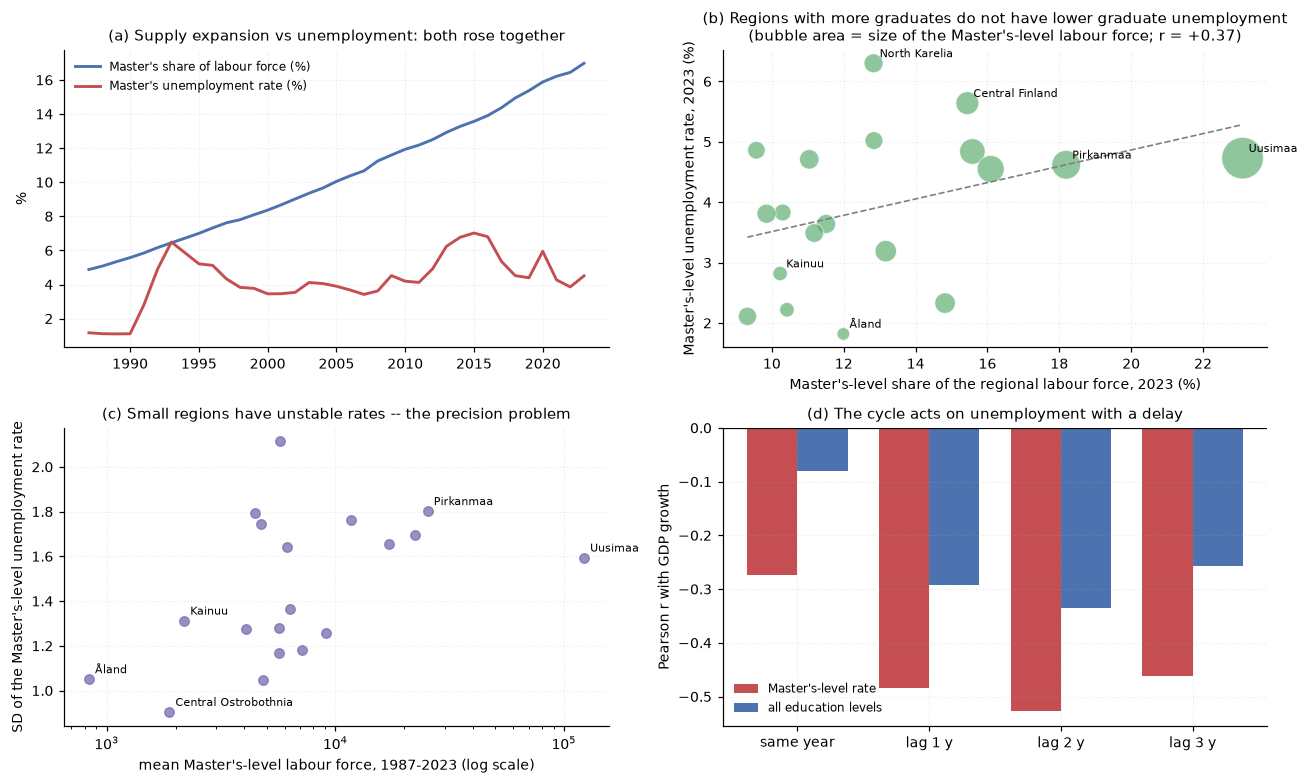

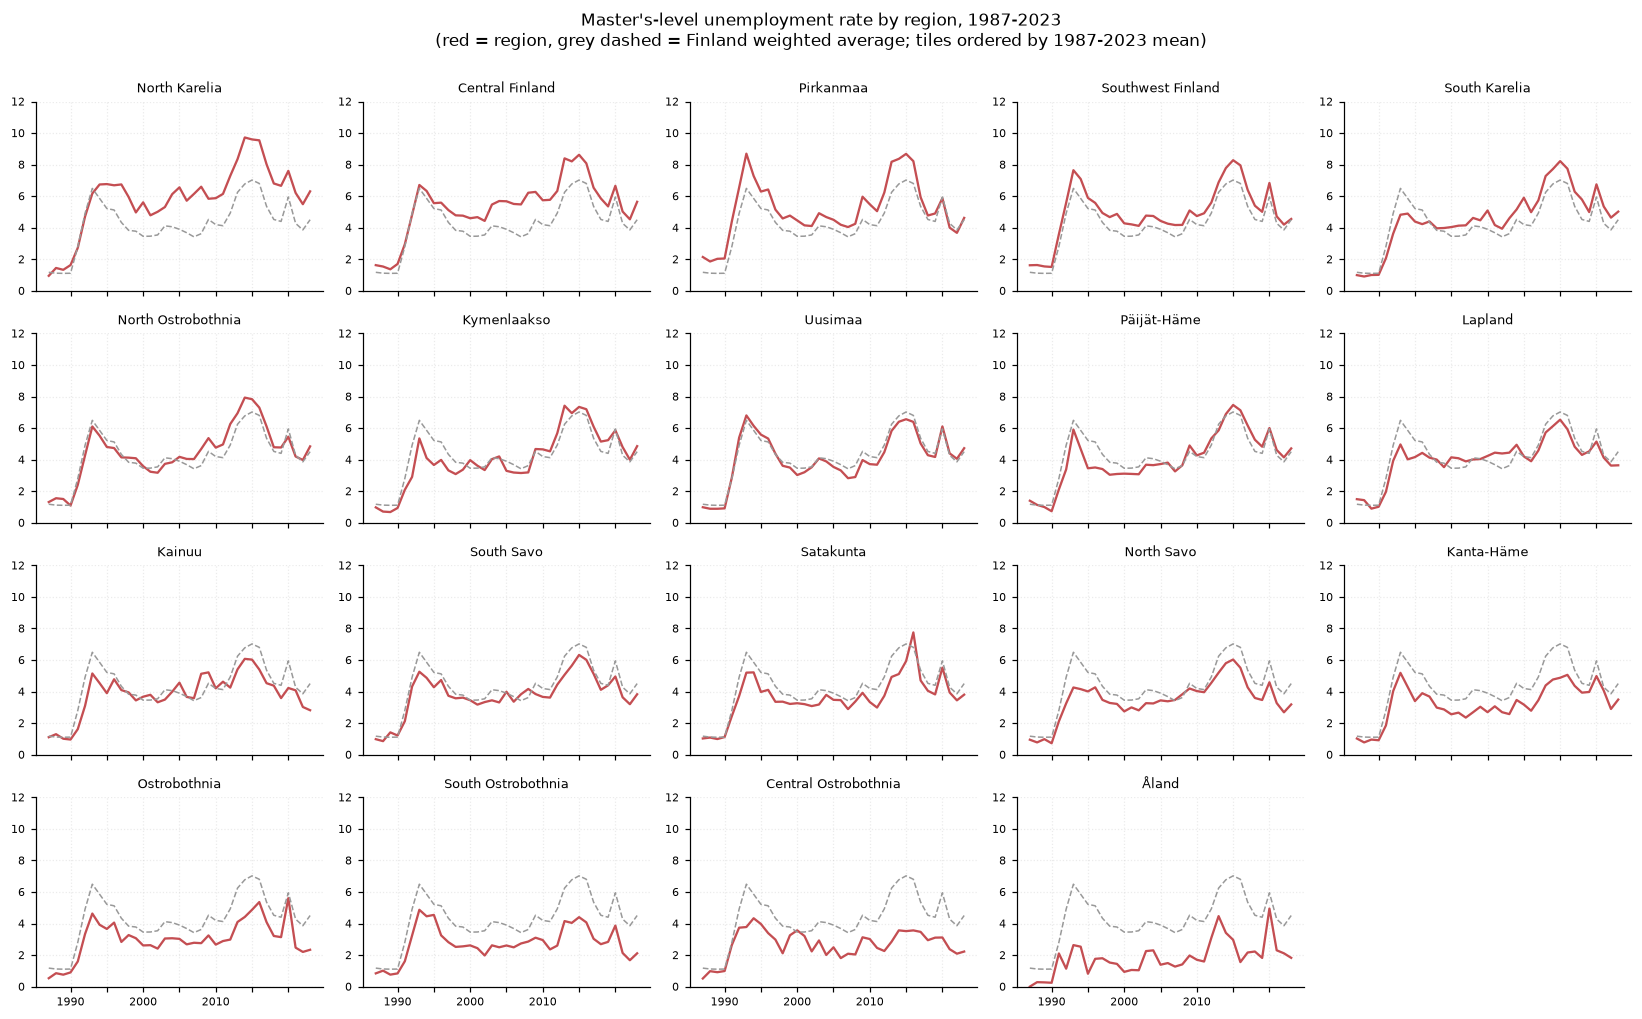

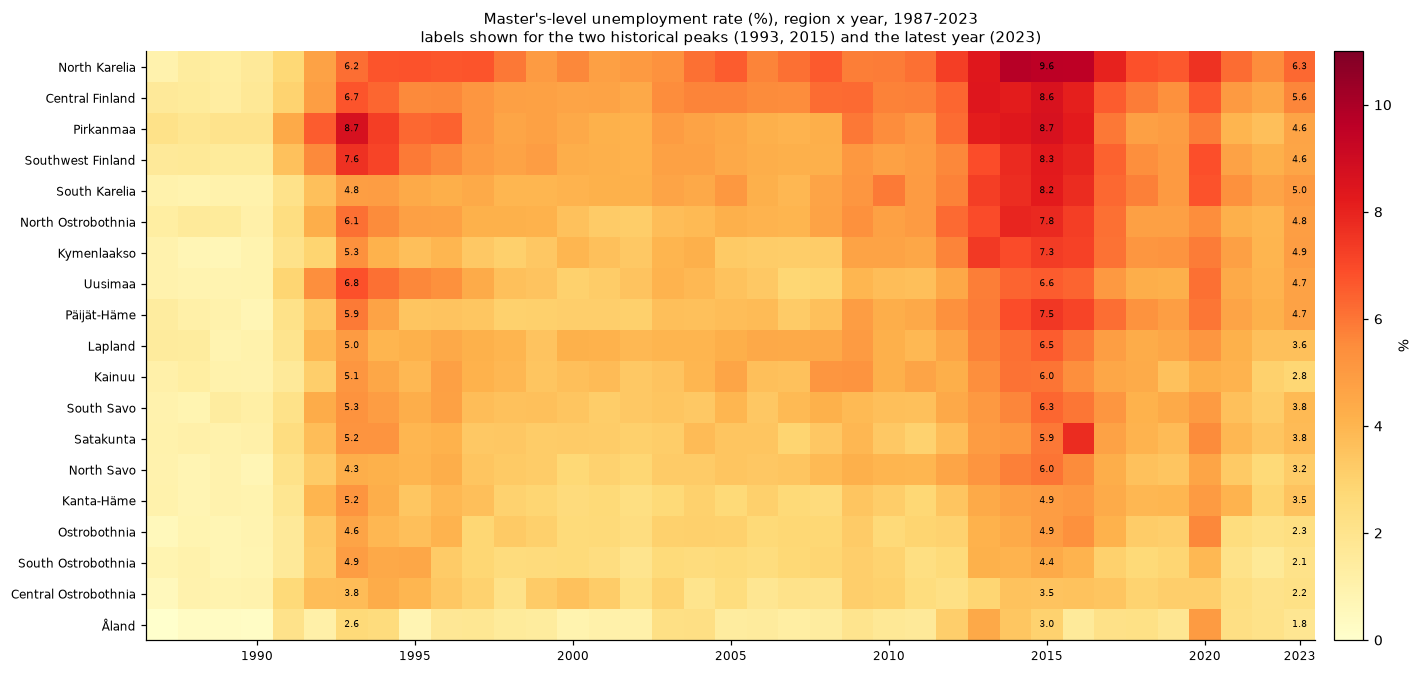

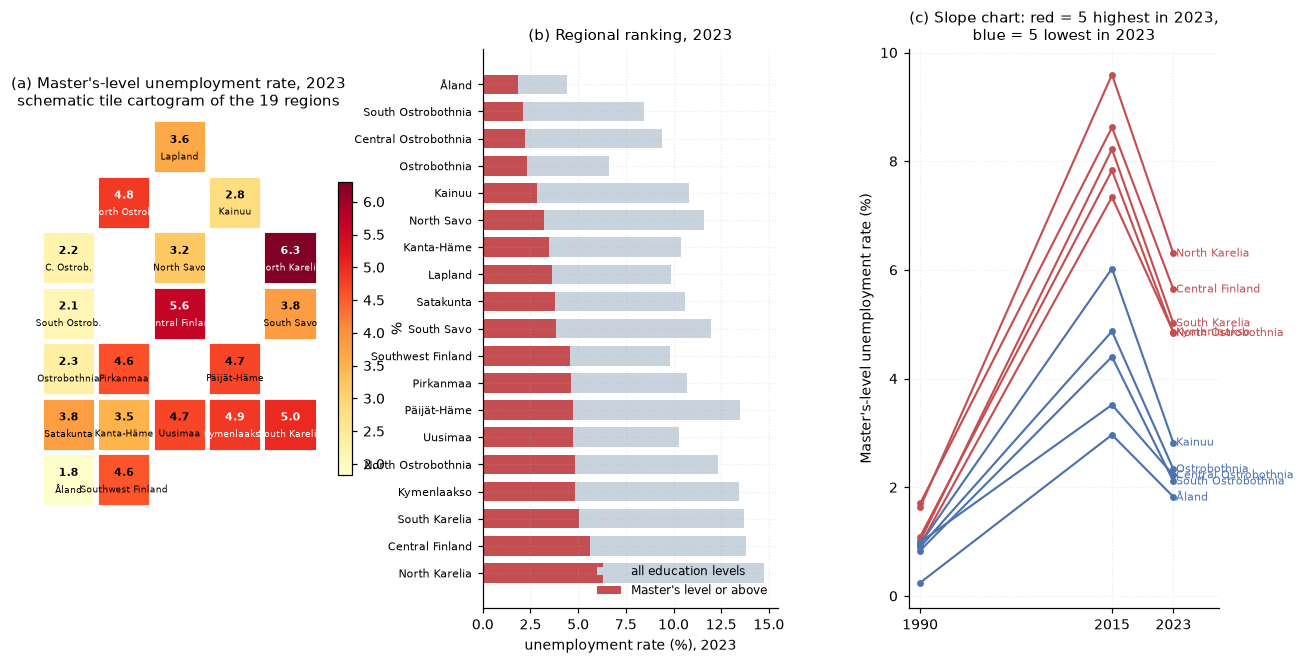

Note: for a true choropleth, install geopandas and join a Finnish region shapefile
(e.g. SYKE / Natural Earth admin-1) on the region name or the MK code; the tile grid
above was chosen because it conveys the same geography with zero extra dependencies.


In [ ]:
## Use this cell for your code

# ============================================================
# Province comparison table
# ============================================================

# regional comparison
piv_rate = w.pivot_table(index="region", columns="Year", values="urate_masters_pct")
piv_tot  = w.pivot_table(index="region", columns="Year", values="urate_total_pct")
piv_cnt  = w.pivot_table(index="region", columns="Year", values="unemp_masters")
piv_lf   = w.pivot_table(index="region", columns="Year", values="lf_masters")

last = int(w["Year"].max())
first = int(w["Year"].min())

reg_sum = pd.DataFrame({
    "MSc LF share %d" % last:   piv_lf[last] / w.pivot_table(index="region", columns="Year", values="lf_total")[last] * 100,
    "unemp. MSc (n) %d" % last: piv_cnt[last],
    "MSc LF (n) %d" % last:     piv_lf[last],
    "MSc rate %d" % last:       piv_rate[last],
    "all rate %d" % last:       piv_tot[last],
    "MSc rate %d" % first:      piv_rate[first],
    "mean %d-%d" % (first, last): piv_rate.mean(axis=1),
    "SD %d-%d" % (first, last):   piv_rate.std(axis=1),
    "peak year":                 piv_rate.idxmax(axis=1),
    "peak rate":                 piv_rate.max(axis=1),
    "protective ratio %d" % last: piv_rate[last] / piv_tot[last],
}).sort_values("MSc rate %d" % last, ascending=False).round(2)

print("=== Regions ranked by Master's-level unemployment rate in %d ===" % last)
print(reg_sum.to_string())

print("\n=== Cross-region dispersion of the Master's-level rate ===")
for y in [1990, 2000, 2015, 2023]:
    v = piv_rate[y]
    print("  %d: min %.2f%% (%s) | median %.2f%% | max %.2f%% (%s) | range %.2f pp"
          % (y, v.min(), v.idxmin(), v.median(), v.max(), v.idxmax(), v.max() - v.min()))

print("\n=== In which year did each region hit its all-time peak? ===")
print(piv_rate.idxmax(axis=1).value_counts().sort_index().to_string())

print("\n=== The raw-count trap (%d) ===" % last)
trap = reg_sum[["unemp. MSc (n) %d" % last, "MSc LF (n) %d" % last, "MSc rate %d" % last]]
print("Top 4 by NUMBER of unemployed Master's-level people:")
print(trap.sort_values("unemp. MSc (n) %d" % last, ascending=False).head(4).to_string())
print("\nTop 4 by RATE (the same year, completely different ranking):")
print(trap.sort_values("MSc rate %d" % last, ascending=False).head(4).to_string())

r_share = np.corrcoef(reg_sum["MSc LF share %d" % last], reg_sum["MSc rate %d" % last])[0, 1]
print("\nAcross regions in %d: corr(Master's share of labour force, Master's rate) = %+.2f" % (last, r_share))

# ============================================================
# Province trends: composition, small multiples, heatmap, cartogram
# ============================================================

# FIGURE 2: composition, small denominators and the two external drivers
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))

# (a) Master's share of the labour force vs Master's rate
ax = axes[0, 0]
ax.plot(merged.index, merged["masters_share_lf_pct"], color="#4c72b0", lw=1.9,
        label="Master's share of labour force (%)")
ax.plot(merged.index, merged["urate_masters_pct"], color="#c44e52", lw=1.9,
        label="Master's unemployment rate (%)")
ax.set_title("(a) Supply expansion vs unemployment: both rose together")
ax.legend(loc="upper left")
ax.set_ylabel("%")

# (b) regional scatter: graduate intensity vs graduate unemployment (latest year)
ax = axes[0, 1]
xs = reg_sum["MSc LF share %d" % last]
ys = reg_sum["MSc rate %d" % last]
ax.scatter(xs, ys, s=np.sqrt(reg_sum["MSc LF (n) %d" % last]) * 1.6,
           c="#55a868", alpha=0.65, edgecolor="white", lw=0.6)
z = np.polyfit(xs, ys, 1)
gx = np.linspace(xs.min(), xs.max(), 50)
ax.plot(gx, np.polyval(z, gx), "--", color="grey", lw=1.1)
for reg in ["Uusimaa", "North Karelia", "Åland", "Central Finland", "Pirkanmaa", "Kainuu"]:
    ax.annotate(reg, (xs[reg], ys[reg]), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Master's-level share of the regional labour force, %d (%%)" % last)
ax.set_ylabel("Master's-level unemployment rate, %d (%%)" % last)
ax.set_title("(b) Regions with more graduates do not have lower graduate unemployment\n"
             "(bubble area = size of the Master's-level labour force; r = %+.2f)"
             % np.corrcoef(xs, ys)[0, 1], fontsize=9.5)

# (c) small denominators: rate volatility vs labour-force size
ax = axes[1, 0]
mean_lf = piv_lf.mean(axis=1)
sd_rate = piv_rate.std(axis=1)
ax.scatter(mean_lf, sd_rate, c="#8172b3", alpha=0.8, s=38)
ax.set_xscale("log")
for reg in ["Åland", "Kainuu", "Central Ostrobothnia", "Uusimaa", "Pirkanmaa"]:
    ax.annotate(reg, (mean_lf[reg], sd_rate[reg]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("mean Master's-level labour force, 1987-2023 (log scale)")
ax.set_ylabel("SD of the Master's-level unemployment rate")
ax.set_title("(c) Small regions have unstable rates -- the precision problem")

# (d) lagged association with the business cycle
ax = axes[1, 1]
lags = [0, 1, 2, 3]
rs_m = [corr("gdp_growth_pct" if l == 0 else "gdp_growth_lag%d" % l, "urate_masters_pct")[0] for l in lags]
rs_t = [corr("gdp_growth_pct" if l == 0 else "gdp_growth_lag%d" % l, "urate_total_pct")[0] for l in lags]
xs2 = np.arange(len(lags))
ax.bar(xs2 - 0.19, rs_m, width=0.38, color="#c44e52", label="Master's-level rate")
ax.bar(xs2 + 0.19, rs_t, width=0.38, color="#4c72b0", label="all education levels")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs2); ax.set_xticklabels(["same year", "lag 1 y", "lag 2 y", "lag 3 y"])
ax.set_ylabel("Pearson r with GDP growth")
ax.set_title("(d) The cycle acts on unemployment with a delay")
ax.legend(loc="lower left")

fig.tight_layout()
plt.show()

# FIGURE 3: every region over time
order = piv_rate.mean(axis=1).sort_values(ascending=False).index.tolist()

fig, axes = plt.subplots(4, 5, figsize=(15, 9.2), sharex=True)
national = w.groupby("Year")["urate_masters_pct"].apply(
    lambda s: np.average(s, weights=w.loc[s.index, "lf_masters"]))

for ax, reg in zip(axes.ravel(), order):
    ax.plot(piv_rate.loc[reg].index, piv_rate.loc[reg].values, color="#c44e52", lw=1.5)
    ax.plot(national.index, national.values, color="#999999", lw=1.0, ls="--")
    ax.set_title(reg, fontsize=8.5)
    ax.set_ylim(0, 12)
    ax.tick_params(labelsize=7)
    for lbl in ax.get_xticklabels()[::2]:
        lbl.set_visible(False)
for ax in axes.ravel()[len(order):]:
    ax.axis("off")
fig.suptitle("Master's-level unemployment rate by region, 1987-2023\n"
             "(red = region, grey dashed = Finland weighted average; tiles ordered by 1987-2023 mean)",
             fontsize=11, y=1.0)
fig.tight_layout()
plt.show()

# FIGURE 4: region x year heatmap (time-geography)
data = piv_rate.loc[order]

fig, ax = plt.subplots(figsize=(13, 6.2))
im = ax.imshow(data.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=11)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)
tick_years = [y for y in data.columns if y % 5 == 0 or y == data.columns.max()]
ax.set_xticks([list(data.columns).index(y) for y in tick_years])
ax.set_xticklabels(tick_years, fontsize=8)
for reg_i in range(len(order)):
    for yr_j, yr in enumerate(data.columns):
        if yr in (1993, 2015, 2023):
            ax.text(yr_j, reg_i, "%.1f" % data.values[reg_i, yr_j], ha="center", va="center",
                    fontsize=6, color="black")
ax.set_title("Master's-level unemployment rate (%), region x year, 1987-2023\n"
             "labels shown for the two historical peaks (1993, 2015) and the latest year (2023)",
             fontsize=10)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.015, label="%")
fig.tight_layout()
plt.show()

# FIGURE 5: geographic tile cartogram + ranking + slope chart
# A schematic tile grid of Finland's 19 regions (rows = latitude, columns = west-east).
# It is a cartogram, not a true map: it needs no shapefile and no extra packages.
TILES = {
    "Lapland":              (0, 2),
    "North Ostrobothnia":   (1, 1), "Kainuu":            (1, 3),
    "Central Ostrobothnia": (2, 0), "North Savo":        (2, 2), "North Karelia": (2, 4),
    "South Ostrobothnia":   (3, 0), "Central Finland":   (3, 2), "South Savo":    (3, 4),
    "Ostrobothnia":         (4, 0), "Pirkanmaa":         (4, 1), "Päijät-Häme":   (4, 3),
    "Satakunta":            (5, 0), "Kanta-Häme":        (5, 1), "Uusimaa":       (5, 2),
    "Kymenlaakso":          (5, 3), "South Karelia":     (5, 4),
    "Åland":                (6, 0), "Southwest Finland": (6, 1),
}

missing = sorted(set(piv_rate.index) - set(TILES))
if missing:
    print("WARNING - regions without a tile:", missing)

fig = plt.figure(figsize=(14, 6.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1.05, 0.95, 1.0], wspace=0.42)

# (a) tile cartogram, latest year
ax = fig.add_subplot(gs[0, 0])
vals = piv_rate[last]
norm = plt.Normalize(vals.min(), vals.max())
cmap = plt.get_cmap("YlOrRd")
for reg, (r, c) in TILES.items():
    v = vals.loc[reg]
    ax.add_patch(plt.Rectangle((c, -r), 0.94, 0.94, facecolor=cmap(norm(v)),
                               edgecolor="white", lw=1.2))
    ax.text(c + 0.47, -r + 0.60, "%.1f" % v, ha="center", va="center", fontsize=7.5,
            color="black" if norm(v) < 0.65 else "white", fontweight="bold")
    ax.text(c + 0.47, -r + 0.30, reg.replace(" Ostrobothnia", " Ostrob.").replace("Central Ostrob.", "C. Ostrob."),
            ha="center", va="center", fontsize=5.6,
            color="black" if norm(v) < 0.65 else "white")
ax.set_xlim(-0.3, 5.2); ax.set_ylim(-6.6, 1.0)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title("(a) Master's-level unemployment rate, %d\nschematic tile cartogram of the 19 regions" % last,
             fontsize=9.5, pad=8)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=ax, fraction=0.045, pad=0.02, label="%")

# (b) ranked bars, latest year: Master's rate vs all-levels rate
ax = fig.add_subplot(gs[0, 1])
ypos = np.arange(len(order))[::-1]
o = piv_rate[last].sort_values()
ax.barh(ypos, piv_tot[last].loc[o.index], color="#c9d3de", height=0.72, label="all education levels")
ax.barh(ypos, o.values, color="#c44e52", height=0.72, label="Master's level or above")
ax.set_yticks(ypos); ax.set_yticklabels(o.index, fontsize=7)
ax.set_xlabel("unemployment rate (%%), %d" % last)
ax.set_title("(b) Regional ranking, %d" % last, fontsize=9.5)
ax.legend(loc="lower right")

# (c) slope chart 1990 -> 2015 -> 2023
ax = fig.add_subplot(gs[0, 2])
years = [1990, 2015, last]
hi = piv_rate[last].sort_values(ascending=False).index[:5].tolist()
lo = piv_rate[last].sort_values().index[:5].tolist()
for reg in hi:
    ax.plot(years, piv_rate.loc[reg, years].values, "-o", ms=3.5, lw=1.4, color="#c44e52")
    ax.text(years[-1] + 0.35, piv_rate.loc[reg, years[-1]], reg, va="center", fontsize=7, color="#c44e52")
for reg in lo:
    ax.plot(years, piv_rate.loc[reg, years].values, "-o", ms=3.5, lw=1.4, color="#4c72b0")
    ax.text(years[-1] + 0.35, piv_rate.loc[reg, years[-1]], reg, va="center", fontsize=7, color="#4c72b0")
ax.set_xticks(years); ax.set_xlim(1988.5, 2029)
ax.set_ylabel("Master's-level unemployment rate (%)")
ax.set_title("(c) Slope chart: red = 5 highest in %d,\nblue = 5 lowest in %d" % (last, last), fontsize=9.5)

fig.tight_layout()
plt.show()

print("Note: for a true choropleth, install geopandas and join a Finnish region shapefile")
print("(e.g. SYKE / Natural Earth admin-1) on the region name or the MK code; the tile grid")
print("above was chosen because it conveys the same geography with zero extra dependencies.")

Reflect briefly on your findings. For example, which features seemed interesting with respect to changes in unemployment among the highly educated population? How do different provinces compare? What should be done to ensure that the number of unemployed highly educated people can be compared fairly across years and provinces? 

**Hint**: should we look at the raw numbers or maybe consider them relative to something else?

Most interesting features: A Master’s degree still protects against unemployment, but much less than before: the Master’s/overall unemployment ratio rose from 0.19 in 1987 to 0.42 in 2023. The 2010s were worse for highly educated people than the 1990s: the Master’s rate peaked at 7.0% in 2015. Unemployment changes track GDP changes strongly in differences (r ≈ −0.72 for Master’s, −0.82 for all levels), with lagged effects. R&D is negatively correlated but is not a strong lever, and the rising graduate share of the labour force is a major confounder.

How provinces compare: In 2023, Master’s unemployment ranged from about 1.8% in Åland to 6.3% in North Karelia, a 4.5 pp spread. Regional rankings are not stable over time: the spread widened to 6.6 pp in 2015 and then narrowed. Regions with more graduates are not necessarily the ones with lower graduate unemployment (cross-region correlation +0.37 in 2023). Small regions such as Åland need caution because their labour forces are very small.

Fair comparison across years and provinces: Do not rely on raw counts. Use rates: unemployed ÷ (employed + unemployed) × 100, with the same numerator, denominator, education classification, reference date and regional definition throughout. Also report counts alongside rates, use moving averages or confidence intervals for small regions, and avoid treating these register-based rates as the official unemployment rate. National GDP/R&D series should not be used for regional inference.

## Exercise 2: AI Act

In this exercise, we ask you to think about the different AI services you come accross in your daily life and consider them in terms of the AI Act's risk pyramid.

1. Brainstorm & List: For 48 hours, keep a log of every application, software, or service you interact with that you suspect uses AI. Think about social media feeds, recommendation engines (Netflix, Spotify, Amazon), grammar checkers, spam filters, navigation apps, and virtual assistants. We'd expect that most of you will be able to identify at least 10 examples.

2. Select & Analyze: Choose three distinct AI systems from your list. For each one, research and describe its primary function and how AI is used to achieve it.

3. Classify the Risk: Using the AI Act's risk pyramid as a guide, classify each of your three chosen AI systems into one of the four categories:
	- Unacceptable Risk: Is the AI system doing something that is explicitly banned (e.g., social scoring, real-time remote biometric identification in public spaces by law enforcement)?
	- High-Risk: Could the system have a significant impact on your safety, fundamental rights, or access to essential services? (e.g., AI used in educational scoring, recruitment, or credit scoring). Justify why it falls into a specific high-risk category listed in Annex III of the Act.
	- Limited or Minimal Risk: Does the system interact with you in a way that should require transparency? (e.g., chatbots, deepfakes, generative AI).

4. Justify Your Reasoning: For each classification, write a short paragraph explaining your decision, referencing specific criteria from the AI Act.

### 1. 48-hour AI service log

| # | Service encountered | Suspected AI function |
|---|---------------------|------------------------|
| 1 | TikTok | "For You" content recommendation |
| 2 | Instagram | Feed/Reels recommendations, suggested accounts |
| 3 | YouTube | Video recommendations, auto-generated captions |
| 4 | Spotify | Music recommendations / AI DJ, personalised playlists |
| 5 | Netflix | Film and series recommendations |
| 6 | Gmail | Spam filtering, Smart Compose writing suggestions |
| 7 | Google Maps | Route optimisation, live traffic and ETA prediction |
| 8 | ChatGPT (app/web) | Generative text assistant (drafting, translation, coding) |
| 9 | Grammarly | Grammar, style and tone suggestions |
| 10 | Duolingo | Adaptive lesson difficulty and learner feedback |
| 11 | LinkedIn | Job and candidate matching, feed ranking |
| 12 | Online job application portal | Automated CV screening / candidate ranking |
| 13 | Mobile banking app | Fraud detection, chatbot support |
| 14 | Siri / voice assistant | Speech recognition and natural-language commands |
| 15 | Microsoft Teams | Noise suppression, meeting transcription/recap |

None of the services I logged appeared to perform a practice banned under Article 5 of the AI Act (such as government-style social scoring or real-time remote biometric identification in public by law enforcement). For the deeper analysis I deliberately chose three systems that sit on three different tiers of the risk pyramid.

---

### 2-4. Selected systems: function, classification and justification

#### System 1 — Automated recruitment / CV screening on an online job application portal → **HIGH RISK**

**Primary function and use of AI.** When submitting an application through the portal, the platform's software parses the uploaded CV, extracts features (skills, education, experience, keywords), scores and ranks applicants against the job description, and in some cases automatically rejects low-ranked candidates before any human sees them. Machine-learning classifiers and NLP/embedding models are trained on historical applications and hiring outcomes to predict which candidates "match" the role.

**Classification and justification.** This is a **high-risk** system under **Annex III, point 4(a)** of the AI Act, which lists AI systems "intended to be used for recruitment or selection of natural persons, notably for placing targeted job advertisements, analysing and filtering job applications and evaluating candidates". An automated screening decision can decisively affect a person's access to employment and livelihood — a fundamental right — and ranking errors or biased training data can systematically disadvantage protected groups. The system therefore triggers the high-risk obligations: a risk-management system (Article 9), data-governance and quality requirements (Article 10), technical documentation and logging (Articles 11-12), transparency and instructions for use (Article 13), **human oversight** (Article 14), and accuracy/robustness (Article 15); deployers such as the employer must also perform a **fundamental rights impact assessment** (Article 27). (LinkedIn-style job *suggestions* that merely surface vacancies without evaluating the applicant would not reach this tier — the decisive factor is that the system filters or evaluates candidates.)

#### System 2 — ChatGPT, a general-purpose generative AI assistant → **LIMITED RISK (transparency obligations)**

**Primary function and use of AI.** ChatGPT is a chat interface built on a large language model: given a user prompt it predicts and generates fluent natural-language answers, drafts, summaries, translations or code. The model is a transformer trained on very large text corpora to predict likely next tokens, and is used here for everyday personal assistance (writing, brainstorming, language help).

**Classification and justification.** For ordinary personal use this is a **limited-risk** system: it is not a safety component of a regulated product (Annex I) and is not used in any of the specifically listed high-risk areas of Annex III, so it does not face the full high-risk regime. It does, however, fall under the **transparency obligations of Article 50(1)**: a system designed to interact directly with people must be designed and deployed so that users are informed they are interacting with AI — which the chat interface does explicitly. Under **Article 50(2)**, where the assistant generates or manipulates image, audio or video content (deepfakes), that content must be labelled as artificially generated; providers of general-purpose AI models also carry obligations such as copyright-policy and training-data summary duties (Article 53). The classification is **context-dependent**: the same model repurposed to screen job applicants, make credit decisions or give medical diagnoses would become a component of a high-risk system and be reclassified accordingly.

#### System 3 — Spotify's music recommendation / personalisation system → **MINIMAL RISK**

**Primary function and use of AI.** Spotify recommends tracks and builds personalised playlists (Discover Weekly, AI DJ) using collaborative-filtering and content-based models: they learn patterns from a user's listening history, saved songs and skips, and from the behaviour of similar listeners, to predict songs the user is likely to enjoy.

**Classification and justification.** This is a **minimal-risk** application. It is neither a safety component of a product under Annex I nor listed in Annex III: being recommended — or not recommended — a song has at most an immaterial effect on safety, fundamental rights or access to essential services, and the user can easily search for and play any content independently. The AI Act therefore imposes no mandatory conformity or human-oversight requirements on it; providers may follow voluntary codes of conduct, and any transparency about how recommendations work is largely governed by other rules (such as the Digital Services Act) rather than by the AI Act's risk regime. The system also differs from ChatGPT in that it does not generate human-like content or interact conversationally, so even the Article 50 transparency duties are not engaged in ordinary playlist personalisation.

---

### Summary of classifications

| System | AI Act category | Key basis |
|---|---|---|
| Automated CV / recruitment screening | **High risk** | Annex III, point 4(a) — recruitment, analysing/filtering applications and evaluating candidates; Articles 9-15, 27 |
| ChatGPT generative assistant (personal use) | **Limited risk** | Article 50(1)-(2) transparency (human-AI interaction; labelling AI-generated content); Article 53 for the GPAI provider |
| Spotify recommendations | **Minimal risk** | Not in Annex I or Annex III; no material impact on rights or safety; no mandatory AI Act obligations |